In [165]:
#install packages
import os
#os.system("pip3 install -r requirements.txt")
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error


In [166]:
#load data
all_player_data_22to25 = pd.read_csv('../data/2022-2025hitter_data_no_minPA.csv')
all_player_data_26 = pd.read_csv('../data/2026hitter_data_no_minPA.csv')
defensive_22to25 = pd.read_csv('../data/2022-2025_defensive.csv')
defensive_26 = pd.read_csv('../data/2026_defensive.csv')
free_agent_25= pd.read_excel('../data/25end_free_agent_data.xlsx')
free_agent_24= pd.read_excel('../data/24end_free_agent_data.xlsx')  
free_agent_25.head()

,Name,Pos,Bats,Thr,Prev Team,Age,Service Time,2025 WAR,Proj WAR,Med Years,Med Total,Med AAV,QO,Signing Team,Years,Total Salary,AAV,Unnamed: 17,playerid
0,Cody Bellinger,RF/CF/LF/1B,L,L,NYY,30,8.160,4.818521,3.562840,5.0,135000000,27000000.0,NaN,NYY,5.0,162500000.0,44750000.0,NaN,15998
1,Kyle Schwarber,DH,L,R,PHI,33,10.086,4.778003,2.913014,4.0,112000000,28000000.0,22025000.0,PHI,5.0,150000000.0,30000000.0,NaN,16478
2,Kyle Tucker,RF/LF,L,R,CHC,29,6.079,4.520800,4.768181,8.0,280000000,35000000.0,22025000.0,LAD,4.0,240000000.0,57195945.0,NaN,18345
3,Ranger Suarez,SP,L,L,PHI,30,6.112,4.091566,3.354864,5.0,125000000,25000000.0,22025000.0,BOS,5.0,130000000.0,26000000.0,NaN,17277
4,Framber Valdez,SP,R,L,HOU,32,6.163,3.953125,3.566605,5.0,140000000,28000000.0,22025000.0,DET,3.0,115000000.0,36523154.0,NaN,17295


In [167]:
#merge datasets to get primary position and defensive stats for each player-season combination
#for the years 2022-2025
primary_position_22to25 = (
    defensive_22to25
    .sort_values("Inn", ascending=False)
    .drop_duplicates(["PlayerId", "Season"])
    [["PlayerId", "Season", "Pos"]]
    .rename(columns={"Pos": "PrimaryPosition"})
)
defensive_stats_22to25 = (
    defensive_22to25
    .groupby(["PlayerId", "Season"], as_index=False)
    .agg(
        OAA=("OAA", lambda x: x.sum(min_count=1)),
        FRV=("FRV", lambda x: x.sum(min_count=1)),
        Inn = ("Inn", lambda x: x.sum(min_count=1))
    )
)

defensive_player_season_22to25 = primary_position_22to25.merge(
    defensive_stats_22to25,
    on=["PlayerId", "Season"],
    how="left",
    validate="one_to_one"
)
defensive_player_season_22to25.duplicated(
    ["PlayerId", "Season"]
).sum()

player_with_position_22to25 = all_player_data_22to25.merge(
    defensive_player_season_22to25,
    on=["PlayerId", "Season"],
    how="left",
    validate="one_to_one"
)

#player_with_position_22to25[player_with_position_22to25["Name"] == "Shohei Ohtani"]
player_with_position_22to25["Eligible"] = True

player_with_position_22to25.loc[
    player_with_position_22to25["PrimaryPosition"] == "P",
    "Eligible"
] = False # remove pitchers from the dataset since we are only modeling hitters

player_with_position_22to25.loc[
    player_with_position_22to25["PlayerId"] == 19755,
    "Eligible"
] = False # remove Shohei Ohtani from the dataset since he is a two-way player and we are only modeling hitters

hitter_22to25 = player_with_position_22to25[
    player_with_position_22to25["Eligible"] == True
].copy()

# Players with no defensive record
hitter_22to25["PrimaryPosition"] = (
    hitter_22to25["PrimaryPosition"]
    .fillna("NoDefense")
)

# Indicator for whether a defensive record exists
hitter_22to25["HasDefense"] = (
    hitter_22to25["PrimaryPosition"] != "NoDefense"
).astype(int)
#hitter_22to25 = player_with_position_22to25[player_with_position_22to25["Eligible"] == True]# create a new dataframe with only eligible hitters
#hitter_22to25.head()

#for the year 2026, we will use the same process to get primary position and defensive stats for each player-season combination
primary_position_26 = (
    defensive_26
    .sort_values("Inn", ascending=False)
    .drop_duplicates(["PlayerId", "Season"])
    [["PlayerId", "Season", "Pos"]]
    .rename(columns={"Pos": "PrimaryPosition"})
)
defensive_stats_26 = (
    defensive_26
    .groupby(["PlayerId", "Season"], as_index=False)
    .agg(
        OAA=("OAA", lambda x: x.sum(min_count=1)),
        FRV=("FRV", lambda x: x.sum(min_count=1)),
        Inn = ("Inn", lambda x: x.sum(min_count=1))
    )
)

defensive_player_season_26 = primary_position_26.merge(
    defensive_stats_26,
    on=["PlayerId", "Season"],
    how="left",
    validate="one_to_one"
)
defensive_player_season_26.duplicated(
    ["PlayerId", "Season"]
).sum()

player_with_position_26 = all_player_data_26.merge(
    defensive_player_season_26,
    on=["PlayerId", "Season"],
    how="left",
    validate="one_to_one"
)

player_with_position_26["Eligible"] = True

player_with_position_26.loc[
    player_with_position_26["PrimaryPosition"] == "P",
    "Eligible"
] = False # remove pitchers from the dataset since we are only modeling hitters

player_with_position_26.loc[
    player_with_position_26["PlayerId"] == 19755,
    "Eligible"
] = False 
hitter_26 = player_with_position_26[
    player_with_position_26["Eligible"] == True
].copy()

hitter_26["PrimaryPosition"] = (
    hitter_26["PrimaryPosition"]
    .fillna("NoDefense")
)

hitter_26["HasDefense"] = (
    hitter_26["PrimaryPosition"] != "NoDefense"
).astype(int)

#hitter_26 = player_with_position_26[player_with_position_26["Eligible"] == True]# create a new dataframe with only eligible hitters
#hitter_26.head()
#hitter_26[hitter_26["PrimaryPosition"].isna()]

defensive_26[
    defensive_26["Name"].str.contains(
        "Yandy", case=False, na=False
    )
]

,Season,Name,Team,Pos,Inn,rSZ,rCERA,rSB,rGDP,rARM,...,ErrR,UZR,UZR/150,FRM,OAA,FRV,Def,NameASCII,PlayerId,MLBAMID


In [69]:
#check missing values
missing_22to25 = hitter_22to25[['Name','Season', 'Age', 'WAR', 'PA','Inn', 'wRC+', 'FRV', 'PlayerId', 'OAA', 'PrimaryPosition']].isnull().sum()
missing_26 = hitter_26[['Name', 'Season', 'Age', 'WAR', 'PA', 'Inn', 'wRC+', 'FRV', 'PlayerId', 'OAA', 'PrimaryPosition']].isnull().sum()
print("Missing values in hitter_22to25:\n", missing_22to25)   
print("================================")
print("Missing values in hitter_26:\n", missing_26)  



Missing values in hitter_22to25:
 Name                 0
Season               0
Age                  0
WAR                  0
PA                   0
Inn                 29
wRC+                 8
FRV                 35
PlayerId             0
OAA                372
PrimaryPosition     29
dtype: int64
Missing values in hitter_26:
 Name                0
Season              0
Age                 0
WAR                 0
PA                  0
Inn                 6
wRC+                2
FRV                 9
PlayerId            0
OAA                90
PrimaryPosition     6
dtype: int64


In [168]:
#check OAA and FRV missing values by position
oaa_missing_by_position = (
    hitter_22to25
    .assign(
        Position=hitter_22to25["PrimaryPosition"].fillna("NoDefense"),
        OAA_Missing=hitter_22to25["OAA"].isna()
    )
    .groupby("Position")
    .agg(
        Total=("PlayerId", "size"),
        Missing_OAA=("OAA_Missing", "sum")
    )
)

oaa_missing_by_position["Missing_Percent"] = (
    oaa_missing_by_position["Missing_OAA"]
    / oaa_missing_by_position["Total"]
    * 100
)

print("Missing OAA by Position:\n", oaa_missing_by_position.sort_values("Missing_OAA", ascending=False))

frv_missing_by_position = (
    hitter_22to25
    .assign(
        Position=hitter_22to25["PrimaryPosition"].fillna("NoDefense"),
        FRV_Missing=hitter_22to25["FRV"].isna()
    )
    .groupby("Position")
    .agg(
        Total=("PlayerId", "size"),
        Missing_FRV=("FRV_Missing", "sum")
    )
)

frv_missing_by_position["Missing_Percent"] = (
    frv_missing_by_position["Missing_FRV"]
    / frv_missing_by_position["Total"]
    * 100
)

print(frv_missing_by_position)  

missing_frv_players = hitter_22to25[
    hitter_22to25["FRV"].isna() &
    hitter_22to25["PrimaryPosition"].notna()
]

missing_frv_players[
    ["Name", "Season", "PrimaryPosition", "PA", "FRV", "Inn"]
]


Missing OAA by Position:
            Total  Missing_OAA  Missing_Percent
Position                                      
C            418          337        80.622010
NoDefense     29           29       100.000000
2B           319            3         0.940439
RF           363            2         0.550964
3B           330            1         0.303030
1B           302            0         0.000000
CF           298            0         0.000000
LF           345            0         0.000000
SS           255            0         0.000000
           Total  Missing_FRV  Missing_Percent
Position                                      
1B           302            0         0.000000
2B           319            3         0.940439
3B           330            1         0.303030
C            418            0         0.000000
CF           298            0         0.000000
LF           345            0         0.000000
NoDefense     29           29       100.000000
RF           363            2     

,Name,Season,PrimaryPosition,PA,FRV,Inn
63,Marcell Ozuna,2025,NoDefense,592,NaN,NaN
238,Kris Bryant,2025,NoDefense,41,NaN,NaN
770,Luis Campusano,2025,NoDefense,27,NaN,NaN
833,David Bañuelos,2025,NoDefense,2,NaN,NaN
900,Terrin Vavra,2025,2B,1,NaN,2.0
940,David Fry,2025,NoDefense,157,NaN,NaN
1485,Giancarlo Stanton,2024,NoDefense,459,NaN,NaN
1501,J.D. Martinez,2024,NoDefense,495,NaN,NaN
1560,Marcell Ozuna,2024,NoDefense,688,NaN,NaN
1600,Joc Pederson,2024,NoDefense,449,NaN,NaN


In [ ]:
#check missing values of wRC+ by position
wrc_missing_by_position = (
    hitter_22to25
    .assign(
        Position=hitter_22to25["PrimaryPosition"].fillna("NoDefense"),
        wRC_Missing=hitter_22to25["wRC+"].isna()
    )
    .groupby("Position")
    .agg(
        Total=("PlayerId", "size"),
        Missing_wRC=("wRC_Missing", "sum")
    )
) 

wrc_missing_by_position["Missing_Percent"] = (
    wrc_missing_by_position["Missing_wRC"]
    / wrc_missing_by_position["Total"]
    * 100
)   

print("Missing wRC+ by Position:\n", wrc_missing_by_position.sort_values("Missing_wRC", ascending=False))

missing_wrc_players = hitter_22to25[
    hitter_22to25["wRC+"].isna()
]  

missing_wrc_players[
    ["Name", "Season", "PrimaryPosition", "PA", "wRC+", "FRV","Inn"]
]   

pa0 = hitter_22to25[
    hitter_22to25["PA"] == 0
]

#check for any players with wRC+ less than -90
#hitter_22to25.loc[hitter_22to25["wRC+"] < -90, ["Name", "Season", "PA", "wRC+", "AVG", "OPS", "HR"] ]

Missing wRC+ by Position:
            Total  Missing_wRC  Missing_Percent
Position                                      
C            418            3         0.717703
2B           319            2         0.626959
NoDefense     29            2         6.896552
3B           330            1         0.303030
1B           302            0         0.000000
CF           298            0         0.000000
LF           345            0         0.000000
RF           363            0         0.000000
SS           255            0         0.000000


,Name,Season,PA,wRC+,AVG,OPS,HR
294,Sergio Alcántara,2025,4,-100.0,0.0,0.0,0
315,Greg Allen,2025,14,-100.0,0.0,0.0,0
325,Aramis Garcia,2025,4,-100.0,0.0,0.0,0
408,Garrett Stubbs,2025,1,-100.0,0.0,0.0,0
551,Chuckie Robinson,2025,2,-100.0,0.0,0.0,0
873,Jordyn Adams,2025,5,-100.0,0.0,0.0,0
900,Terrin Vavra,2025,1,-100.0,0.0,0.0,0
949,Justin Dean,2025,2,-100.0,0.0,0.0,0
973,Greg Jones,2025,2,-100.0,0.0,0.0,0
1012,C.J. Stubbs,2025,3,-100.0,0.0,0.0,0


In [173]:
#check duplicated data
print(hitter_22to25.duplicated(subset=["PlayerId", "MLBAMID", "Season"]).sum())
print(hitter_26.duplicated(subset=["PlayerId", "MLBAMID", "Season"]).sum())


0
0


In [172]:
#check wrong value
print((hitter_26[["Age", "PA", "Season", "Inn"]] < 0).sum())
print((hitter_22to25[["Age", "PA", "Season", "Inn"]] <0).sum())


Age       0
PA        0
Season    0
Inn       0
dtype: int64
Age       0
PA        0
Season    0
Inn       0
dtype: int64


In [171]:
# check the how many players are there in each year of the dataset
transition_counts = []

for year in [2022, 2023, 2024]:

    current_players = set(
        hitter_22to25.loc[
            hitter_22to25["Season"] == year,
            "PlayerId"
        ]
    )

    next_players = set(
        hitter_22to25.loc[
            hitter_22to25["Season"] == year + 1,
            "PlayerId"
        ]
    )

    both = current_players & next_players

    transition_counts.append({
        "Transition": f"{year} → {year + 1}",
        "N_current": len(current_players),
        "N_next": len(next_players),
        "N_both_seasons": len(both)
    })

transition_counts = pd.DataFrame(transition_counts)

N_position = len(hitter_22to25)
N_position_players = hitter_22to25["PlayerId"].nunique()

print("N_position:", N_position)
print("Unique eligible position players:", N_position_players)

print("Transition Counts:")
print(transition_counts)    

players_all_4_years = (
    hitter_22to25
    .groupby("PlayerId")["Season"]
    .nunique()
)

players_all_4_years = players_all_4_years[
    players_all_4_years == 4
]

print("Players appearing in all 4 seasons:", len(players_all_4_years))

free_agent_25 = free_agent_25.rename(
    columns={"playerid": "PlayerId"}
)
hitter_22to25["PlayerId"] = hitter_22to25["PlayerId"].astype(str)
free_agent_25["PlayerId"] = free_agent_25["PlayerId"].astype(str)

free_agent_candidates = hitter_22to25[
    hitter_22to25["Season"] == 2025
].merge(
    free_agent_25[["PlayerId"]].drop_duplicates(),
    on="PlayerId",
    how="inner"
)

N_free_agent_candidates = (
    free_agent_candidates["PlayerId"].nunique()
)

print("N_free_agent_candidates:", N_free_agent_candidates)

validation_population = []

for year in [2022, 2023, 2024]:

    current_players = set(
        hitter_22to25.loc[
            hitter_22to25["Season"] == year,
            "PlayerId"
        ]
    )

    next_players = set(
        hitter_22to25.loc[
            hitter_22to25["Season"] == year + 1,
            "PlayerId"
        ]
    )

    returning = current_players & next_players
    entrants = next_players - current_players
    exits = current_players - next_players

    validation_population.append({
        "Validation_Period": f"{year} → {year + 1}",
        "Distinct_Players": len(next_players),
        "Returning_Players": len(returning),
        "Entrants": len(entrants),
        "Exits": len(exits)
    })

validation_population = pd.DataFrame(validation_population)

validation_population


N_position: 2659
Unique eligible position players: 1037
Transition Counts:
    Transition  N_current  N_next  N_both_seasons
0  2022 → 2023        689     654             529
1  2023 → 2024        654     649             514
2  2024 → 2025        649     667             534
Players appearing in all 4 seasons: 342
N_free_agent_candidates: 106


,Validation_Period,Distinct_Players,Returning_Players,Entrants,Exits
0,2022 → 2023,654,529,125,160
1,2023 → 2024,649,514,135,140
2,2024 → 2025,667,534,133,115


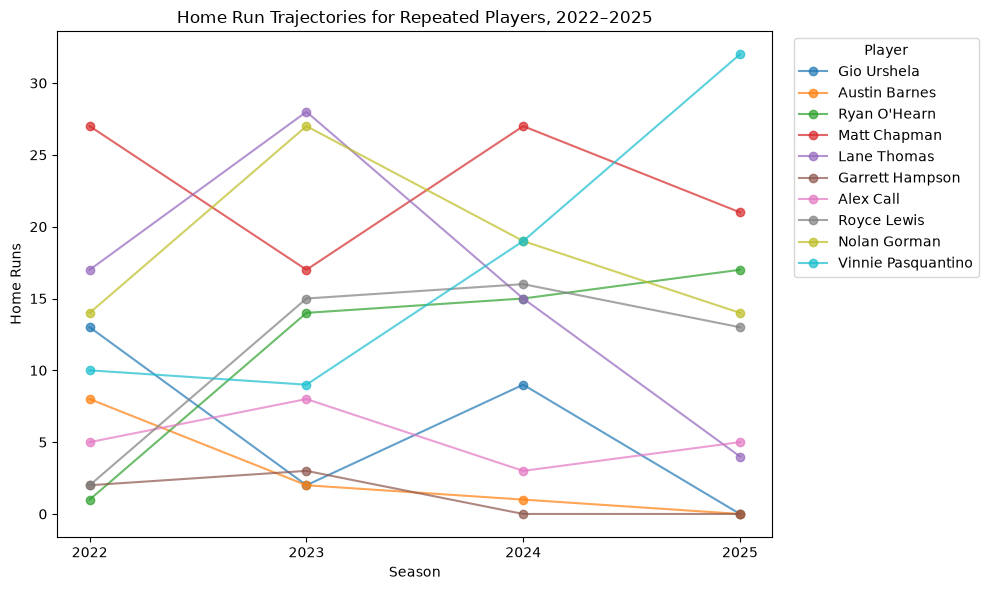

In [170]:
season_count = (
    hitter_22to25[hitter_22to25["PA"] > 0]
    .groupby("PlayerId")["Season"]
    .nunique()
)

four_year_players = season_count[
    season_count == 4
].index

sample_players = (
    hitter_22to25[
        hitter_22to25["PlayerId"].isin(four_year_players)
        & (hitter_22to25["PA"] > 0)
    ]["PlayerId"]
    .drop_duplicates()
    .sample(10, random_state=42)
)
plot_data = hitter_22to25[
    hitter_22to25["PlayerId"].isin(sample_players)
    & (hitter_22to25["PA"] > 0)
]

plt.figure(figsize=(10, 6))

for player_id, group in plot_data.groupby("PlayerId"):
    group = group.sort_values("Season")
    player_name = group["Name"].dropna().iloc[0] if not group["Name"].dropna().empty else str(player_id)

    plt.plot(
        group["Season"],
        group["HR"],
        marker="o",
        alpha=0.7,
        label=player_name
    )

plt.xlabel("Season")
plt.ylabel("Home Runs")
plt.title("Home Run Trajectories for Repeated Players, 2022–2025")
plt.xticks([2022, 2023, 2024, 2025])
plt.legend(title="Player", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()

In [174]:
# HR correlation between current and next year

current = hitter_22to25[
    ["PlayerId", "Season", "HR"]
].copy()

next_year = hitter_22to25[
    ["PlayerId", "Season", "HR"]
].copy()

next_year["Season"] = next_year["Season"] - 1
next_year = next_year.rename(columns={"HR": "HR_next"})

hr_pairs = current.merge(
    next_year,
    on=["PlayerId", "Season"]
)

print("the correlation between current and next year's home runs is:", hr_pairs["HR"].corr(hr_pairs["HR_next"]))


# HR per PA correlation between current and next year

current = hitter_22to25[
    ["PlayerId", "Season", "HR", "PA"]
].copy()

current["HR_per_PA"] = current["HR"] / current["PA"]

next_year = current[
    ["PlayerId", "Season", "HR_per_PA"]
].copy()

next_year["Season"] = next_year["Season"] - 1
next_year = next_year.rename(columns={"HR_per_PA": "HR_per_PA_next"})

hr_pairs = current.merge(
    next_year,
    on=["PlayerId", "Season"]
)

# Remove invalid values from PA = 0
hr_pairs = hr_pairs.replace([float("inf"), -float("inf")], float("nan"))
hr_pairs = hr_pairs.dropna(subset=["HR_per_PA", "HR_per_PA_next"])

print(
    "Correlation between current and next year's HR per PA:",
    hr_pairs["HR_per_PA"].corr(hr_pairs["HR_per_PA_next"])
)

the correlation between current and next year's home runs is: 0.6774674606425043
Correlation between current and next year's HR per PA: 0.3881128275128242


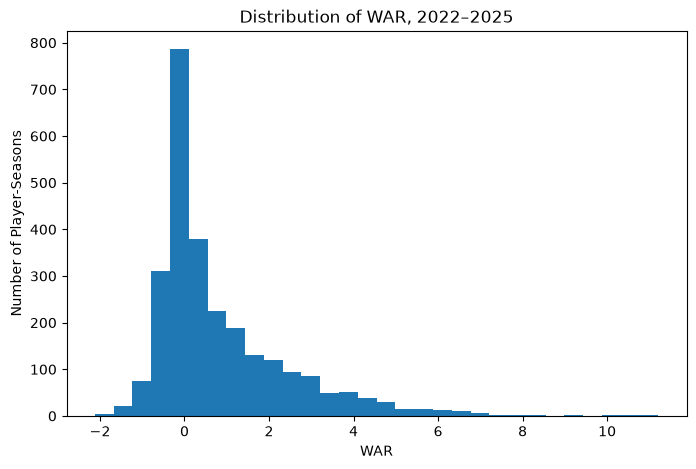

In [175]:
# Distribution of WAR, 2022–2025

plt.figure(figsize=(8, 5))

plt.hist(
    hitter_22to25["WAR"].dropna(),
    bins=30,
)
plt.xlabel("WAR")
plt.ylabel("Number of Player-Seasons")
plt.title("Distribution of WAR, 2022–2025")
plt.savefig('../figures/war_distribution_2022-2025.png', dpi=300, bbox_inches='tight')
plt.show()


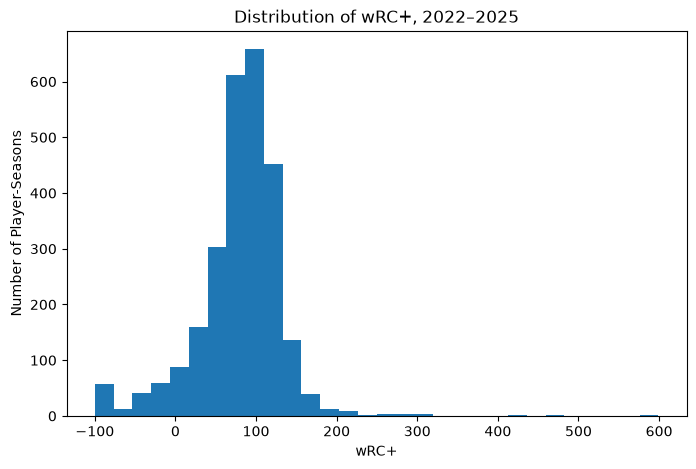

In [115]:

plt.figure(figsize=(8, 5))

plt.hist(
    hitter_22to25["wRC+"].dropna(),
    bins=30,
)

plt.xlabel("wRC+")
plt.ylabel("Number of Player-Seasons")
plt.title("Distribution of wRC+, 2022–2025")
plt.savefig('../figures/wrc_distribution_2022-2025.png', dpi=300, bbox_inches='tight')
plt.show()

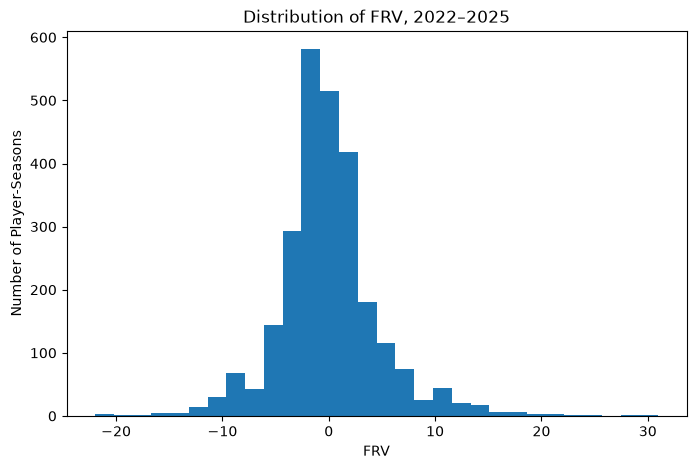

In [116]:
plt.figure(figsize=(8, 5))

plt.hist(
    hitter_22to25["FRV"].dropna(),
    bins=30,
)

plt.xlabel("FRV")
plt.ylabel("Number of Player-Seasons")
plt.title("Distribution of FRV, 2022–2025")
plt.savefig('../figures/frv_distribution_2022-2025.png', dpi=300, bbox_inches='tight')
plt.show()

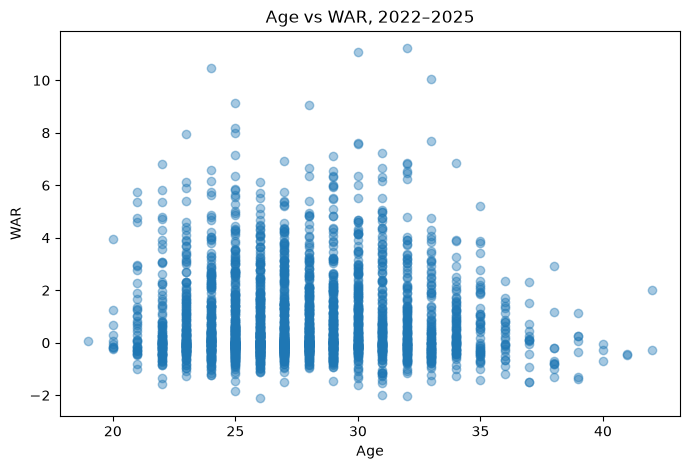

In [176]:
# Age vs WAR, 2022–2025 
plt.figure(figsize=(8, 5))

plt.scatter(
    hitter_22to25["Age"],
    hitter_22to25["WAR"],
    alpha=0.4
)

plt.xlabel("Age")
plt.ylabel("WAR")
plt.title("Age vs WAR, 2022–2025")
plt.savefig('../figures/age_war_scatter_2022-2025.png', dpi=300, bbox_inches='tight')
plt.show()

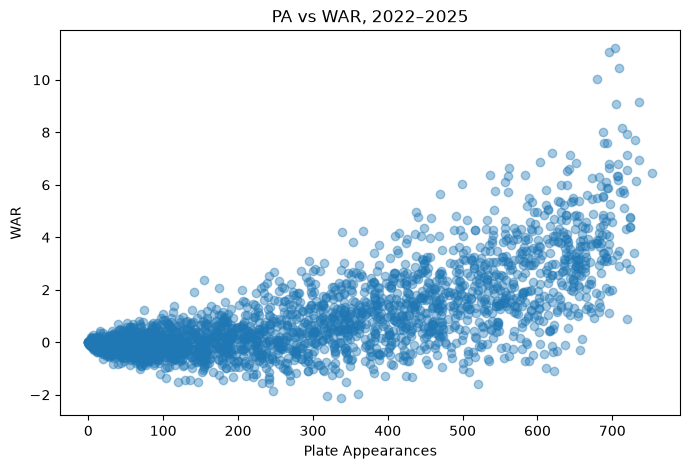

In [177]:
# PA vs WAR, 2022–2025 (PA >= 200)
plt.figure(figsize=(8, 5))
plt.scatter(
    hitter_22to25["PA"],
    hitter_22to25["WAR"],
    alpha=0.4
)

plt.xlabel("Plate Appearances")
plt.ylabel("WAR")
plt.title("PA vs WAR, 2022–2025")
plt.savefig('../figures/pa_war_scatter_2022-2025.png', dpi=300, bbox_inches='tight')
plt.show()

In [178]:
war_current = hitter_22to25[
    ["PlayerId", "Name", "Season", "WAR"]
].copy()

war_current = war_current.rename(
    columns={"WAR": "WAR_t"}
)
war_next = hitter_22to25[
    ["PlayerId", "Season", "WAR"]
].copy()

war_next = war_next.rename(
    columns={
        "Season": "NextSeason",
        "WAR": "WAR_next"
    }
)

war_next["Season"] = war_next["NextSeason"] - 1

war_pairs = war_current.merge(
    war_next,
    on=["PlayerId", "Season"],
    how="inner",
    validate="one_to_one"
)

#war_pairs.head()

war_pairs["Transition"] = (
    war_pairs["Season"].astype(str)
    + " → "
    + war_pairs["NextSeason"].astype(str)
)

assert (
    war_pairs["NextSeason"] ==
    war_pairs["Season"] + 1
).all()

war_corr = war_pairs["WAR_t"].corr(
    war_pairs["WAR_next"]
)

print(f"Overall WAR correlation: {war_corr:.3f}")

war_corr_by_year = (
    war_pairs
    .groupby("Transition")
    .apply(
        lambda x: x["WAR_t"].corr(x["WAR_next"])
    )
    .reset_index(name="WAR_Correlation")
)

war_corr_by_year

Overall WAR correlation: 0.610


,Transition,WAR_Correlation
0,2022 → 2023,0.626110
1,2023 → 2024,0.554668
2,2024 → 2025,0.648297


In [179]:
#dependency between seasons and teams
season_summary = (
    hitter_22to25
    .groupby("Season")
    .agg(
        N_Players=("PlayerId", "nunique"),
        Mean_WAR=("WAR", "mean"),
        Median_WAR=("WAR", "median"),
        SD_WAR=("WAR", "std"),
        Mean_wRC_plus=("wRC+", "mean"),
        Mean_FRV=("FRV", "mean")
    )
    .reset_index()
)

print("Dependent between seasons:\n", season_summary,"\n")


team_season_summary = (
    hitter_22to25
    .groupby(["Season", "Team"])
    .agg(
        N_Players=("PlayerId", "nunique"),
        Mean_WAR=("WAR", "mean"),
        Median_WAR=("WAR", "median"),
        Mean_wRC_plus=("wRC+", "mean")
    )
    .reset_index()
)

print("Dependent between teams:\n", team_season_summary.sort_values(["Mean_WAR"], ascending=[False]).head(10), "\n")

Dependent between seasons:
    Season  N_Players  Mean_WAR  Median_WAR    SD_WAR  Mean_wRC_plus  Mean_FRV
0    2022        689  0.822151    0.209446  1.622295      78.987914 -0.081001
1    2023        654  0.861584    0.272756  1.587682      82.467073 -0.068217
2    2024        649  0.864818    0.256097  1.643985      81.448920 -0.035994
3    2025        667  0.843395    0.185366  1.605231      76.626561 -0.090772 

Dependent between teams:
      Season Team  N_Players  Mean_WAR  Median_WAR  Mean_wRC_plus
29     2022  TOR         15  2.187390    2.370620     131.000879
113    2025  NYY         15  2.172031    0.958054     105.540205
33     2023  ATL         19  2.158408    0.711090     107.847136
99     2025  CHC         16  2.034610    2.048830     105.970749
45     2023  LAD         15  2.022630    1.243950      97.794697
14     2022  LAD         17  2.008156    1.449756      91.819183
122    2025  TOR         17  1.905289    1.818373      99.268921
19     2022  NYY         18  1.879

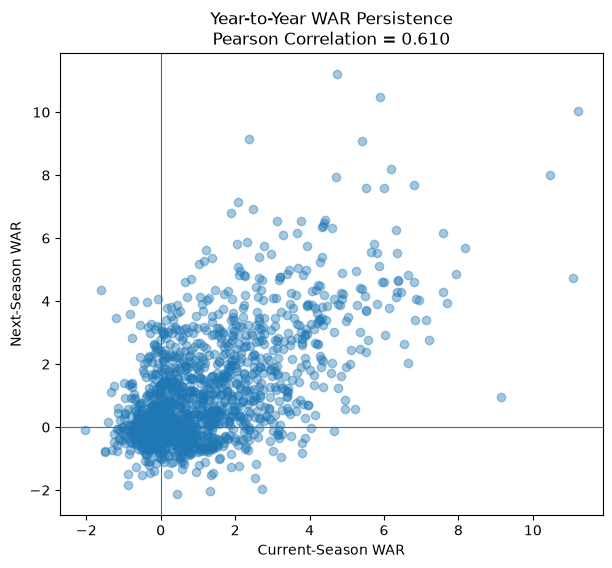

In [127]:

plt.figure(figsize=(7, 6))

plt.scatter(
    war_pairs["WAR_t"],
    war_pairs["WAR_next"],
    alpha=0.4
)

plt.xlabel("Current-Season WAR")
plt.ylabel("Next-Season WAR")
plt.title(
    f"Year-to-Year WAR Persistence\n"
    f"Pearson Correlation = {war_corr:.3f}"
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.savefig('../figures/war_persistence_scatter_2022-2025.png', dpi=300, bbox_inches='tight')
plt.show()

In [180]:
# Current-season and next-season information table

current_data = hitter_22to25[
    [
        "PlayerId",
        "Name",
        "Season",
        "Age",
        "WAR",
        "PA",
        "wRC+",
        "FRV",
        "PrimaryPosition",
        "HasDefense"
    ]
].copy()

# Rename current-season variables
current_data = current_data.rename(
    columns={
        "Season": "DecisionYear",
        "WAR": "WAR_t",
        "PA": "PA_t",
        "wRC+": "wRC+_t",
        "FRV": "FRV_t",
        "Age": "Age_t",
        "PrimaryPosition": "Position_t",
        "HasDefense": "HasDefense_t"
    }
)

# Next-season WAR target
next_war = hitter_22to25[
    ["PlayerId", "Season", "WAR"]
].copy()

next_war = next_war.rename(
    columns={
        "Season": "TargetYear",
        "WAR": "WAR_next"
    }
)

# Decision year is one year before target year
next_war["DecisionYear"] = (
    next_war["TargetYear"] - 1
)

player_decision_year = current_data.merge(
    next_war,
    on=["PlayerId", "DecisionYear"],
    how="inner",
    validate="one_to_one"
)


player_decision_year = player_decision_year[
    [
        "PlayerId",
        "Name",
        "DecisionYear",
        "TargetYear",
        "Age_t",
        "WAR_t",
        "wRC+_t",
        "FRV_t",
        "PA_t",
        "Position_t",
        "HasDefense_t",
        "WAR_next"
    ]
]
player_decision_year.head(10)

,PlayerId,Name,DecisionYear,TargetYear,Age_t,WAR_t,wRC+_t,FRV_t,PA_t,Position_t,HasDefense_t,WAR_next
0,2396,Carlos Santana,2024,2025,38,2.931903,113.218310,9.0,594,1B,1,0.257205
1,2967,Tommy Pham,2024,2025,36,-0.052262,91.869081,-6.0,478,RF,1,0.144950
2,4940,Jason Heyward,2024,2025,34,0.840989,92.974265,1.0,258,RF,1,-0.520233
3,4949,Giancarlo Stanton,2024,2025,34,0.760850,116.071399,NaN,459,NoDefense,0,1.894012
4,5235,Justin Turner,2024,2025,39,1.132467,116.372725,-1.0,539,1B,1,-0.275928
5,5361,Freddie Freeman,2024,2025,34,3.925636,135.557808,2.0,638,1B,1,3.875796
6,5417,Jose Altuve,2024,2025,34,3.888652,127.313142,-5.0,682,2B,1,2.188207
7,5517,Kyle Higashioka,2024,2025,34,1.583023,104.650227,-2.0,263,C,1,1.012415
8,5827,Wilmer Flores,2024,2025,32,-0.644788,68.644278,-2.0,242,1B,1,-0.212083
9,6887,Martín Maldonado,2024,2025,37,-1.500968,11.957832,-8.0,147,C,1,-0.770528


In [159]:
# Persistence baseline:

# Keep only rows with both current-season WAR and next-season WAR
baseline_data = player_decision_year[
    [
        "PlayerId",
        "Name",
        "DecisionYear",
        "TargetYear",
        "WAR_t",
        "WAR_next"
    ]
].dropna().copy()

# predicted next-season WAR = current-season WAR
baseline_data["WAR_pred_baseline"] = baseline_data["WAR_t"]

# Absolute error
baseline_data["Absolute_Error"] = abs(
    baseline_data["WAR_next"]
    - baseline_data["WAR_pred_baseline"]
)

# Residual = actual - predicted
baseline_data["Residual"] = (
    baseline_data["WAR_next"]
    - baseline_data["WAR_pred_baseline"]
)

# Overall MAE
baseline_mae = mean_absolute_error(
    baseline_data["WAR_next"],
    baseline_data["WAR_pred_baseline"]
)

# Overall bias
mean_residual = baseline_data["Residual"].mean()

print(f"Overall Persistence Baseline MAE: {baseline_mae:.3f} WAR")
print(f"Mean Residual: {mean_residual:.3f} WAR")
print(f"N: {len(baseline_data)}")

baseline_by_year = (
    baseline_data
    .groupby(["DecisionYear", "TargetYear"])
    .agg(
        N=("PlayerId", "size"),
        Baseline_MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

baseline_by_year["Transition"] = (
    baseline_by_year["DecisionYear"].astype(str)
    + " → "
    + baseline_by_year["TargetYear"].astype(str)
)

baseline_by_year = baseline_by_year[
    [
        "Transition",
        "N",
        "Baseline_MAE",
        "Mean_Residual"
    ]
]

print(baseline_by_year) 

Overall Persistence Baseline MAE: 1.110 WAR
Mean Residual: -0.093 WAR
N: 1577
    Transition    N  Baseline_MAE  Mean_Residual
0  2022 → 2023  529      1.101222      -0.116804
1  2023 → 2024  514      1.160312      -0.078335
2  2024 → 2025  534      1.070239      -0.083667


  Age_Group    N       MAE  Mean_Residual
0       <25  352  1.269243       0.379312
1     25-29  813  1.019429      -0.128649
2     30-34  366  1.165485      -0.397736
3       35+   46  1.050401      -0.654049


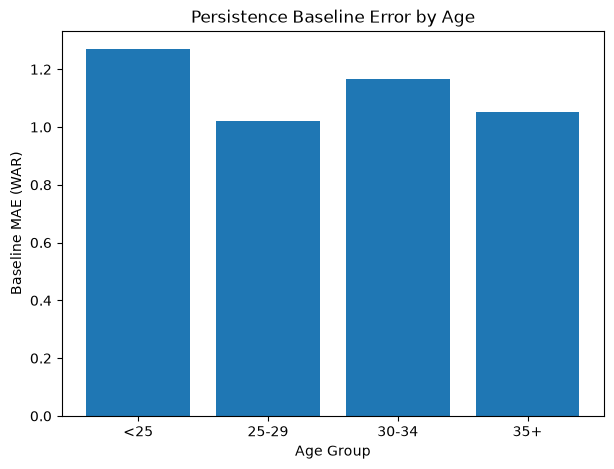

In [ ]:
# error by age of group

error_data = player_decision_year[
    [
        "PlayerId",
        "Name",
        "DecisionYear",
        "TargetYear",
        "Age_t",
        "PA_t",
        "Position_t",
        "WAR_t",
        "WAR_next"
    ]
].dropna(
    subset=["WAR_t", "WAR_next"]
).copy()

# Persistence baseline
error_data["WAR_pred_baseline"] = error_data["WAR_t"]

# Error
error_data["Residual"] = (
    error_data["WAR_next"]
    - error_data["WAR_pred_baseline"]
)

error_data["Absolute_Error"] = abs(
    error_data["Residual"]
)

error_data["Age_Group"] = pd.cut(
    error_data["Age_t"],
    bins=[0, 24, 29, 34, 100],
    labels=[
        "<25",
        "25-29",
        "30-34",
        "35+"
    ]
)

age_error = (
    error_data
    .groupby("Age_Group", observed=True)
    .agg(
        N=("PlayerId", "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

print(age_error)

In [ ]:
#error by position group
position_error = (
    error_data
    .groupby("Position_t", dropna=False)
    .agg(
        N=("PlayerId", "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

print(position_error)

,Position_t,N,MAE,Mean_Residual
4,CF,186,1.342197,-0.092321
7,SS,167,1.326968,-0.002088
8,NaN,13,1.158174,-0.070759
0,1B,161,1.080060,-0.222047
1,2B,184,1.078671,-0.313287
5,LF,222,1.074128,0.023975
6,RF,201,1.069031,-0.111554
2,3B,199,1.035227,-0.086616
3,C,244,0.952621,-0.002297


In [ ]:
#error by prior season PA
error_data["PA_Group"] = pd.cut(
    error_data["PA_t"],
    bins=[-1, 99, 299, 499, float("inf")],
    labels=[
        "0-99",
        "100-299",
        "300-499",
        "500+"
    ]
)

pa_error = (
    error_data
    .groupby("PA_Group", observed=True)
    .agg(
        N=("PlayerId", "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

print(pa_error)

,PA_Group,N,MAE,Mean_Residual
0,0-99,331,0.633100,0.315086
1,100-299,425,0.941172,0.253320
2,300-499,428,1.181302,-0.247377
3,500+,393,1.616548,-0.643279
